<a href="https://colab.research.google.com/github/harleenk2295-cpu/c-practice/blob/main/disrMat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.metrics.pairwise import cosine_similarity

# Load the heart disease dataset (replace with your actual path)
df = pd.read_csv('/content/archive (3).zip')

# Features and target variable
X = df.drop('target', axis=1)
y = df['target']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the features (important for distance-based metrics)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize k-NN classifier with a chosen value of k
k = 5
knn = KNeighborsClassifier(n_neighbors=k)

# 1. **Using Manhattan Distance (p=1)**
knn_manhattan = KNeighborsClassifier(n_neighbors=k, metric='manhattan')
knn_manhattan.fit(X_train_scaled, y_train)
y_pred_manhattan = knn_manhattan.predict(X_test_scaled)
accuracy_manhattan = accuracy_score(y_test, y_pred_manhattan)

# 2. **Using Minkowski Distance (p=3)**
knn_minkowski = KNeighborsClassifier(n_neighbors=k, metric='minkowski', p=3)
knn_minkowski.fit(X_train_scaled, y_train)
y_pred_minkowski = knn_minkowski.predict(X_test_scaled)
accuracy_minkowski = accuracy_score(y_test, y_pred_minkowski)

# 3. **Using Cosine Similarity**
# For Cosine similarity, k-NN does not natively support this, but we can create a custom distance metric function
def cosine_dist(x, y):
    return 1 - cosine_similarity(x.reshape(1, -1), y.reshape(1, -1))

knn_cosine = KNeighborsClassifier(n_neighbors=k, metric=cosine_dist)
knn_cosine.fit(X_train_scaled, y_train)
y_pred_cosine = knn_cosine.predict(X_test_scaled)
accuracy_cosine = accuracy_score(y_test, y_pred_cosine)

# Output results
print(f"Accuracy with Manhattan Distance: {accuracy_manhattan}")
print(f"Accuracy with Minkowski Distance (p=3): {accuracy_minkowski}")
print(f"Accuracy with Cosine Similarity: {accuracy_cosine}")





Accuracy with Manhattan Distance: 0.8360655737704918
Accuracy with Minkowski Distance (p=3): 0.9016393442622951
Accuracy with Cosine Similarity: 0.9016393442622951


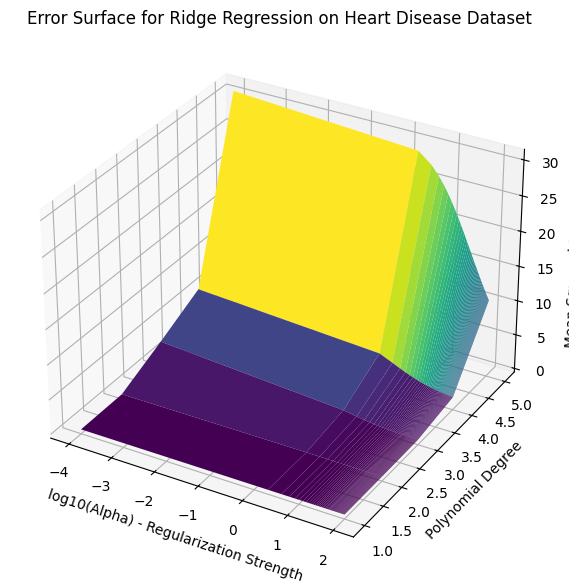

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_squared_error

# Load the heart disease dataset
df = pd.read_csv('/content/archive (3).zip')

# Features and target variable
X = df.drop('target', axis=1)
y = df['target']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


alpha_values = np.linspace(0.0001, 100, 50)  # 50 evenly spaced alpha values between 0.0001 and 100
degree_values = np.arange(1, 6)  # Polynomial degree from 1 to 5

# Prepare the error surface matrix
error_surface = np.zeros((len(degree_values), len(alpha_values)))

# Loop over polynomial degrees and alpha values to compute the error rates
for i, degree in enumerate(degree_values):
    # Create polynomial features
    poly = PolynomialFeatures(degree)
    X_train_poly = poly.fit_transform(X_train_scaled)
    X_test_poly = poly.transform(X_test_scaled)

    for j, alpha in enumerate(alpha_values):
        # Initialize Ridge Regression with current alpha
        ridge_reg = Ridge(alpha=alpha)

        # Train the model
        ridge_reg.fit(X_train_poly, y_train)

        # Make predictions
        y_pred = ridge_reg.predict(X_test_poly)

        # Compute the Mean Squared Error (MSE)
        mse = mean_squared_error(y_test, y_pred)
        error_surface[i, j] = mse  # Store the MSE in the error surface matrix

# Plot the error surface in 3D
alpha_values_grid, degree_values_grid = np.meshgrid(alpha_values, degree_values)

# Create a 3D plot
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Plot the error surface
ax.plot_surface(np.log10(alpha_values_grid), degree_values_grid, error_surface, cmap='viridis',
edgecolor='none')

# Labels and title
ax.set_xlabel('log10(Alpha) - Regularization Strength')
ax.set_ylabel('Polynomial Degree')
ax.set_zlabel('Mean Squared Error (MSE)')
ax.set_title('Error Surface for Ridge Regression on Heart Disease Dataset')

# Show the plot
plt.show()